## TF-IDF baseline for ternary AI-text detection

> This version uses the 256-token truncated dataset (aligned with the Frozen RoBERTa approach) instead of the untruncated one.

In [1]:
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, accuracy_score)

In [2]:
# connect to a runtime and upload dataset
DATA_PATH = 'data\\ternary_academic_wiki_256.csv'
SEED = 42
VAL_SIZE = 0.15
LABELS = ['human', 'ai_generated', 'ai_refined']

In [3]:
# load dataset

df = pd.read_csv(DATA_PATH)
display(df.head())

,text,label,pair_id,lang,model,domain,split
0,"Susan Summerall Wiles (born May 14, 1957) is a...",human,36403,english,deepseek-v3,Wiki,train
1,Susan Wiles Susan Summerall Wiles (born May 14...,ai_generated,36403,english,deepseek-v3,Wiki,train
2,"Susan Summerall Wiles (born May 14, 1957) is a...",ai_refined,36403,english,deepseek-v3,Wiki,train
3,"In algebraic geometry, a period is a number th...",human,36404,english,deepseek-v3,Wiki,train
4,Period (Algebraic Geometry) In algebraic geome...,ai_generated,36404,english,deepseek-v3,Wiki,train


In [4]:
# preliminary analysis

print("class distribution:")
print(df["label"].value_counts())
print("\ntrain/test split distribution:")
print(df["split"].value_counts())

class distribution:
label
human           2500
ai_generated    2500
ai_refined      2500
Name: count, dtype: int64

train/test split distribution:
split
train    6000
test     1500
Name: count, dtype: int64


In [5]:
# test splits

train_raw = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()

split = GroupShuffleSplit()

train_idx, val_idx = next(split.split(train_raw, groups=train_raw["pair_id"]))
train = train_raw.iloc[train_idx].copy()
validation = train_raw.iloc[val_idx].copy()

print("split sizes:")
print("training:", len(train))
print("validation:", len(validation))
print("testing:", len(test))

split sizes:
training: 4800
validation: 1200
testing: 1500


In [6]:
# train baseline model (tf-idf + log regression)

baseline = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", LogisticRegression(random_state=SEED))
])

baseline.fit(train["text"], train["label"])

,steps,"[('tfidf', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,input,'content'
,encoding,'utf-8'
,decode_error,'strict'
,strip_accents,None
,lowercase,True
,preprocessor,None
,tokenizer,None


Test accuracy: 0.7947
Test macro-F1: 0.796

Classification report:
              precision    recall  f1-score   support

       human     0.8109    0.8660    0.8375       500
ai_generated     0.9146    0.7280    0.8107       500
  ai_refined     0.6954    0.7900    0.7397       500

    accuracy                         0.7947      1500
   macro avg     0.8070    0.7947    0.7960      1500
weighted avg     0.8070    0.7947    0.7960      1500



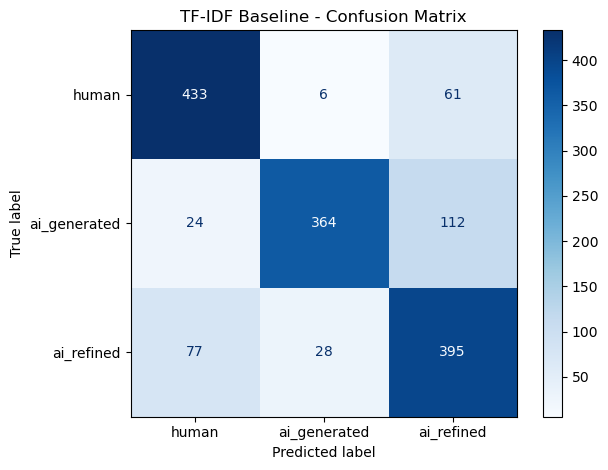


Error counts by true and predicted labels:


prediction,ai_generated,ai_refined,human
label,,,
ai_generated,364,112,24
ai_refined,28,395,77
human,6,61,433



Accuracy by domain:


,count,mean
domain,,
Academic,750,0.840000
Wiki,750,0.749333



Accuracy by model:


,count,mean
model,,
deepseek-v3,378,0.783069
gemini-2.5-flash,378,0.835979
gpt-4o,372,0.801075
qwen-max,372,0.758065


In [7]:
# evaluation

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# 1. Quantitative evaluation
y_pred = baseline.predict(test["text"])
y_true = test["label"]

print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Test macro-F1:", round(f1_score(y_true, y_pred, average="macro"), 4))

print("\nClassification report:")
print(classification_report(
    y_true,
    y_pred,
    labels=["human", "ai_generated", "ai_refined"],
    digits=4,
    zero_division=0
))

# 2. Confusion matrix
labels = ["human", "ai_generated", "ai_refined"]

ConfusionMatrixDisplay.from_predictions(
    y_true,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues",
    values_format="d"
)

plt.title("TF-IDF Baseline - Confusion Matrix")
plt.tight_layout()
plt.show()

# 3. Error distribution
results = test.copy()
results["prediction"] = y_pred
results["correct"] = results["label"] == results["prediction"]

print("\nError counts by true and predicted labels:")
display(pd.crosstab(results["label"], results["prediction"]))

print("\nAccuracy by domain:")
display(results.groupby("domain")["correct"].agg(["count", "mean"]))

print("\nAccuracy by model:")
display(results.groupby("model")["correct"].agg(["count", "mean"]))

In [8]:
import numpy as np
from IPython.display import display

# QUALITATIVE ANALYSIS

results = results.copy()
results["word_count"] = (
    results["text"].fillna("").str.split().str.len()
)
results["correct"] = (
    results["label"] == results["prediction"]
)

# incorrect classifications

errors = results[~results["correct"]].copy()

selected_errors = []

for (actual, predicted), group in errors.groupby(
    ["label", "prediction"]
):
    # shortest incorrect example
    short = group.nsmallest(1, "word_count").copy()
    short["selection"] = "Shortest incorrect"

    # longest incorrect example
    long = group.drop(short.index).nlargest(
        1, "word_count"
    ).copy()
    long["selection"] = "Longest incorrect"

    # random incorrect example
    remaining = group.drop(
        short.index.union(long.index)
    )
    random_ex = remaining.sample(
        n=min(1, len(remaining)),
        random_state=42
    ).copy()
    random_ex["selection"] = "Random incorrect"

    selected_errors.extend([short, long, random_ex])

incorrect_examples = pd.concat(
    selected_errors, ignore_index=True
)

# correct classification

correct = results[results["correct"]].copy()

correct_examples = (
    correct.groupby("label", group_keys=False)
    .sample(n=1, random_state=42)
    .copy()
)

correct_examples["selection"] = "Random correct"

# combine & display

qualitative_examples = pd.concat(
    [incorrect_examples, correct_examples],
    ignore_index=True
)

for _, row in qualitative_examples.iterrows():
    print("\n" + "=" * 80)
    print("selection:", row["selection"])
    print("actual:", row["label"])
    print("predicted:", row["prediction"])
    print("domain:", row["domain"])
    print("model:", row["model"])
    print("ID:", row["pair_id"])
    print("word count:", row["word_count"])
    print("\nTEXT:")
    print(row["text"])



selection: Shortest incorrect
actual: ai_generated
predicted: ai_refined
domain: Academic
model: gpt-4o
ID: 111349
word count: 118

TEXT:
The research detailed the synthesis and characterization of salts derived from 1-butyl-3-methylimidazolium ([bm-Im]) and transition metal chlorides, specifically FeCl3, CoCl2, NiCl2, and CuCl2. The synthetic approach began with the preparation of [bm-Im]FeCl4, achieved through a controlled 3-hour reaction at ambient temperature. To ensure the purity of the product, the crude material was meticulously washed with diethyl ether, followed by vacuum drying. This process resulted in high-purity [bm-Im]FeCl4, whose molecular integrity was vital for subsequent experiments. Extending this methodology, the researchers synthesized additional complexes by reacting [bm-Im]Cl with other metal chlorides (CoCl2, NiCl2, CuCl2) in a 2:1 molar ratio. These reactions were carried out in ethanol, a solvent selected for its ability to facilitate homogeneous mixing of th